# Reunião de acompanhamento (2026-07-27) — diagnóstico de cobertura em z da âncora aórtica (etapa 6 v2)

Síntese, sem análise nova, da investigação de 2026-07-16 a 2026-07-27 sobre a falha de cobertura
do bbox calibrado pela âncora da aorta (etapa 6 v2). Recapitulando o achado que motivou tudo:
calibrado com o maior split de treino disponível (`train90`, 88 casos), o bbox ficou grande demais
— **480×414×312 voxels em resolução integral**, `Rv` (redução volumétrica) de só **~5%** (às vezes
negativo) — e a cobertura em val/test não chega a 100% (ver
[docs/step6v2_aorta_anchor.md](../docs/step6v2_aorta_anchor.md), seção "Execução do lote completo
(1000 imagens) — concluída (2026-07-16), achado bloqueante novo").

Este notebook reúne, **sem reprocessar nenhuma imagem/máscara**, os artefatos já gerados nas
sessões de diagnóstico subsequentes, com foco no eixo z. Não é uma análise nova nem propõe
correção — é material de apoio para a conversa com o orientador; a decisão sobre os próximos
passos é do Hélder.

In [1]:
# ruff: noqa: E402

import sys
from pathlib import Path

NOTEBOOK_CWD = Path.cwd().resolve()
for candidate in (
    NOTEBOOK_CWD,
    NOTEBOOK_CWD.parent,
    NOTEBOOK_CWD.parent.parent,
):
    src_dir = candidate / "src"
    if src_dir.exists():
        if str(src_dir) not in sys.path:
            sys.path.insert(0, str(src_dir))
        break

from utils.project.notebook_env import configure_notebook_environment  # noqa: E402

REPO_ROOT = configure_notebook_environment()
print(f"REPO_ROOT = {REPO_ROOT}")


REPO_ROOT = G:\DAC\heart-bounding-box


In [2]:
import json

import matplotlib
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DIAG_DIR = REPO_ROOT / "output" / "bounding_box" / "aorta_anchor_z_diagnosis"
PROD_DIR = REPO_ROOT / "output" / "bounding_box" / "aorta_anchor"

EXPECTED_FILES = {
    "quintile_csv": DIAG_DIR / "num_circles_quintile_coverage.csv",
    "mask_leak_csv": DIAG_DIR / "mask_leak_quantification_summary.csv",
    "all_cases_csv": PROD_DIR / "all_cases.csv",
    "img_924": DIAG_DIR / "img" / "case_924_z_inspection.png",
    "img_622": DIAG_DIR / "img" / "case_622_z_inspection.png",
    "img_44": DIAG_DIR / "img" / "case_44_z_inspection.png",
}
for label, path in EXPECTED_FILES.items():
    if not path.exists():
        print(f"AVISO: {label} não encontrado em {path} — listando diretório...")
        for candidate in sorted(path.parent.glob("*")):
            print(f"  - {candidate.name}")
        raise FileNotFoundError(
            f"Ajuste o nome esperado para {label}: nenhum arquivo correspondente em {path.parent}"
        )
print("Todos os arquivos esperados existem, nenhum reprocessamento necessário:")
for label, path in EXPECTED_FILES.items():
    print(f"  {label}: {path.relative_to(REPO_ROOT)}")


Todos os arquivos esperados existem, nenhum reprocessamento necessário:
  quintile_csv: output\bounding_box\aorta_anchor_z_diagnosis\num_circles_quintile_coverage.csv
  mask_leak_csv: output\bounding_box\aorta_anchor_z_diagnosis\mask_leak_quantification_summary.csv
  all_cases_csv: output\bounding_box\aorta_anchor\all_cases.csv
  img_924: output\bounding_box\aorta_anchor_z_diagnosis\img\case_924_z_inspection.png
  img_622: output\bounding_box\aorta_anchor_z_diagnosis\img\case_622_z_inspection.png
  img_44: output\bounding_box\aorta_anchor_z_diagnosis\img\case_44_z_inspection.png


## 2. Falha de cobertura por quintil de `num_circles_detected` — gráfico central

Divide os 906 casos de val+test (fora da calibração) em quintis de `num_circles_detected`
(quantidade de círculos rastreados pelo Hough na segmentação da aorta) e mostra a taxa de falha de
cobertura por eixo, em cada faixa. Dados de
[num_circles_quintile_coverage.csv](../output/bounding_box/aorta_anchor_z_diagnosis/num_circles_quintile_coverage.csv)
(diagnóstico de 2026-07-24).

In [3]:
quintile_df = pd.read_csv(DIAG_DIR / "num_circles_quintile_coverage.csv")
quintile_df


,quintil,num_circles_min,num_circles_max,n,n_fail_y,taxa_fail_y_%,n_fail_x,taxa_fail_x_%,n_fail_z,taxa_fail_z_%
0,1,2.0,83.0,182,12,6.593407,6,3.296703,11,6.043956
1,2,84.0,99.0,186,1,0.537634,1,0.537634,0,0.000000
2,3,100.0,112.0,176,1,0.568182,4,2.272727,0,0.000000
3,4,113.0,130.0,187,0,0.000000,2,1.069519,0,0.000000
4,5,131.0,275.0,175,8,4.571429,3,1.714286,7,4.000000


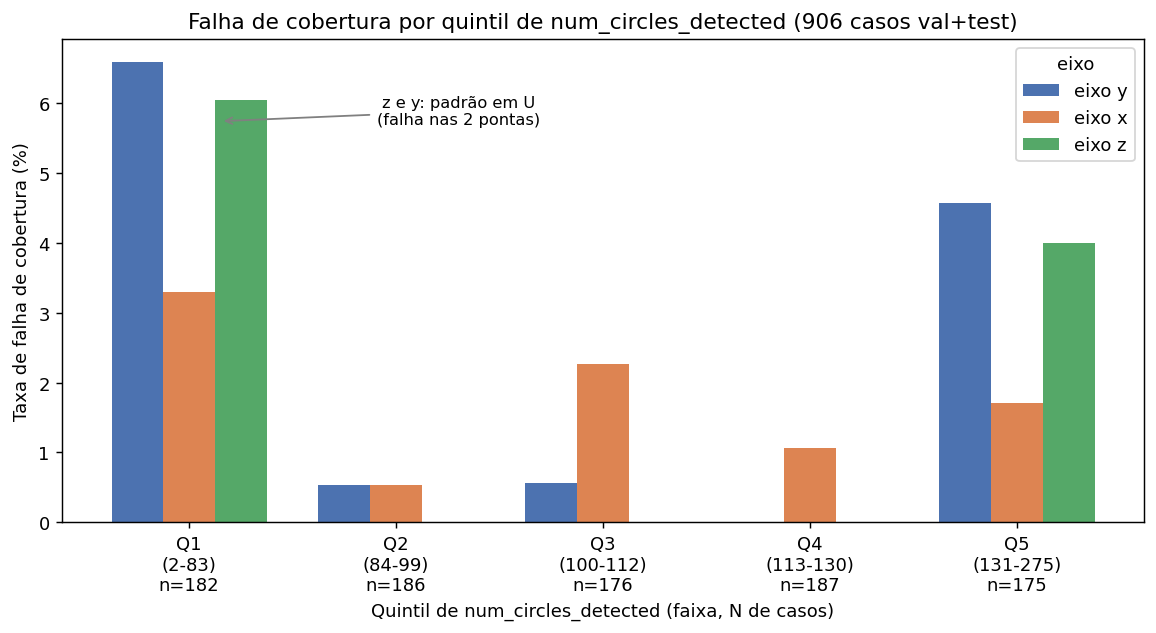

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(quintile_df))
width = 0.25
axes_cols = [
    ("taxa_fail_y_%", "y", "#4C72B0"),
    ("taxa_fail_x_%", "x", "#DD8452"),
    ("taxa_fail_z_%", "z", "#55A868"),
]
for i, (col, label, color) in enumerate(axes_cols):
    ax.bar(x + (i - 1) * width, quintile_df[col], width, label=f"eixo {label}", color=color)

labels = [
    f"Q{row.quintil}\n({row.num_circles_min:.0f}-{row.num_circles_max:.0f})\nn={row.n}"
    for row in quintile_df.itertuples()
]
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_xlabel("Quintil de num_circles_detected (faixa, N de casos)")
ax.set_ylabel("Taxa de falha de cobertura (%)")
ax.set_title("Falha de cobertura por quintil de num_circles_detected (906 casos val+test)")
ax.legend(title="eixo")
ax.annotate(
    "z e y: padrão em U\n(falha nas 2 pontas)",
    xy=(0.15, quintile_df.loc[0, "taxa_fail_z_%"] - 0.3),
    xytext=(1.3, 5.7),
    fontsize=9,
    ha="center",
    arrowprops=dict(arrowstyle="->", color="gray"),
)
fig.tight_layout()
plt.show()


**Leitura dos números**: falha de cobertura em z é **zero** nas três faixas centrais de
`num_circles_detected` (quintis 2, 3 e 4 — de 84 a 130 círculos, ~55% dos 906 casos) e concentrada
inteiramente nas duas faixas extremas — quintil 1 (2-83 círculos, 11 falhas) e quintil 5 (131-275
círculos, 7 falhas). As 18 falhas de z se dividem 11+7 entre as duas pontas — **100% das falhas de
z vêm dos extremos**. O eixo y mostra o mesmo formato em U (12+8 de 22 falhas nas pontas). O eixo x
**não** segue esse padrão de forma tão limpa — maior taxa isolada na faixa central (quintil 3,
2,27%), mais plano/ruidoso.

**Interpretação**: um padrão em U — falha tanto com poucos quanto com muitos círculos rastreados —
é consistente com a hipótese de que **tanto under-tracking quanto over-tracking** da aorta
(mecanismos distintos, ambos ligados à detecção de círculos, não à anatomia do paciente)
contribuem para a falha de cobertura em z, não um único mecanismo numa ponta só.

## 3. Os casos que definiram a calibração original também são outliers

Os 5 `img_id` que definiram os extremos por eixo na calibração original (2026-07-16,
`argmin/argmax_case_per_axis` de `calibration_imagecas_splits_train90.json`), contra a distribuição
de `num_circles_detected` na população de 994 casos processados.

In [5]:
all_cases = pd.read_csv(PROD_DIR / "all_cases.csv")
ok = all_cases[all_cases["status"] == "ok"].copy()

calibration_extreme_cases = {
    934: "y_min",
    428: "y_max/x_min",
    90: "x_max",
    23: "z_min",
    44: "z_max",
}

rows = []
for img_id, axis in calibration_extreme_cases.items():
    n_circles = float(ok.loc[ok["img_id"] == img_id, "num_circles_detected"].iloc[0])
    percentile = 100 * (ok["num_circles_detected"] < n_circles).mean()
    rows.append(
        {
            "img_id": img_id,
            "eixo_definido": axis,
            "num_circles_detected": n_circles,
            "percentil_populacao_994": round(percentile, 1),
        }
    )

extreme_table = pd.DataFrame(rows)
print(
    f"População (994 casos): mediana={ok['num_circles_detected'].median():.0f}  "
    f"média={ok['num_circles_detected'].mean():.1f}  std={ok['num_circles_detected'].std():.1f}"
)
extreme_table


População (994 casos): mediana=106  média=107.7  std=32.9


,img_id,eixo_definido,num_circles_detected,percentil_populacao_994
0,934,y_min,162.0,95.9
1,428,y_max/x_min,172.0,97.2
2,90,x_max,139.0,86.7
3,23,z_min,28.0,1.7
4,44,z_max,186.0,97.9


**Os 5 caem todos numa faixa extrema (quintil 1 ou 5) — nenhum no meio da distribuição.** Os
casos que forçaram os extremos do bbox calibrado (e portanto o tamanho de 480×414×312) parecem
ser, em boa parte, outliers de rastreamento Hough+Level Set — não necessariamente pacientes com
anatomia coronária mais extrema de verdade. Correlação, não causalidade estabelecida.

## 4. Volume da máscara da aorta: casos-problema vs. referência

Volume total da máscara da aorta (voxels) nos 10 casos já investigados (5 piores casos de
cobertura em z + os 5 que definiram a calibração), comparado à referência de **IMG_ID=1 (336.651
voxels, validado manualmente como caso "normal")**. Dados de
[mask_leak_quantification_summary.csv](../output/bounding_box/aorta_anchor_z_diagnosis/mask_leak_quantification_summary.csv)
(diagnóstico de 2026-07-25).

In [6]:
mask_leak_df = pd.read_csv(DIAG_DIR / "mask_leak_quantification_summary.csv")
REFERENCE_VOLUME_VOXELS = 336_651
mask_leak_df[["grupo", "img_id", "eixo_calibracao", "mask_volume_voxels", "volume_ratio_vs_ref"]]


,grupo,img_id,eixo_calibracao,mask_volume_voxels,volume_ratio_vs_ref
0,piores_cobertura_z,622,NaN,1569468,4.662003
1,piores_cobertura_z,196,NaN,1667441,4.953026
2,piores_cobertura_z,790,NaN,724192,2.151165
3,piores_cobertura_z,924,NaN,1836,0.005454
4,piores_cobertura_z,777,NaN,16986,0.050456
5,extremo_calibracao,934,y_min,681114,2.023205
6,extremo_calibracao,428,y_max/x_min,536221,1.592810
7,extremo_calibracao,90,x_max,489841,1.455041
8,extremo_calibracao,23,z_min,66303,0.196949
9,extremo_calibracao,44,z_max,1024748,3.043948


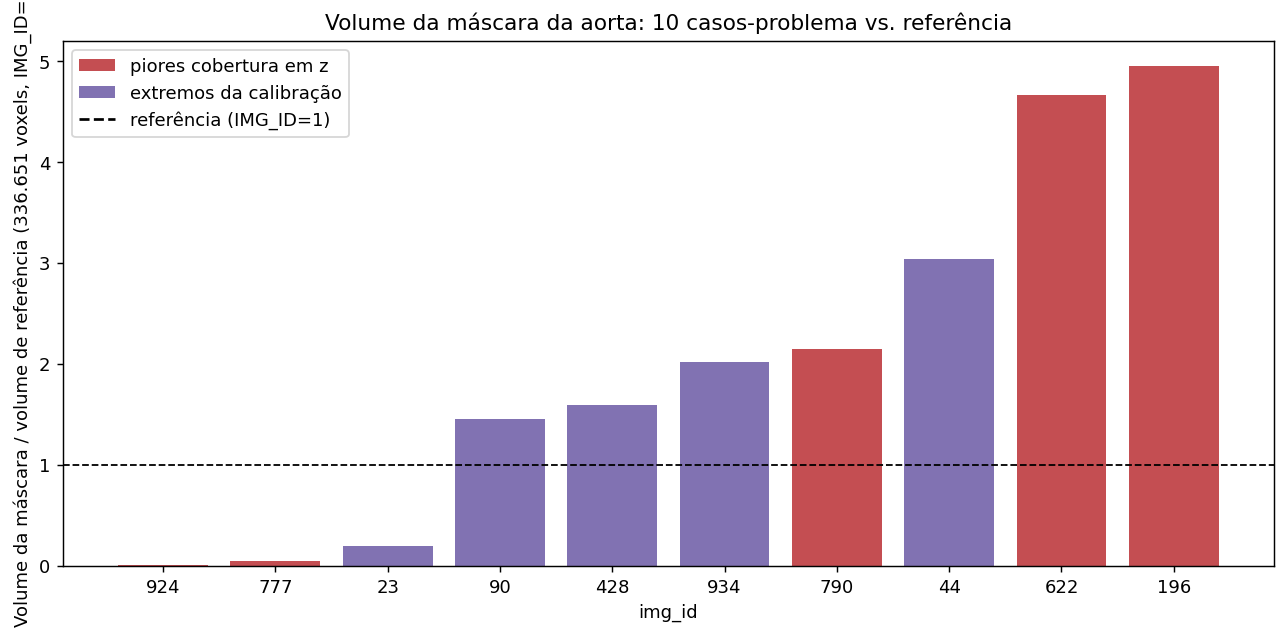

In [7]:
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(10, 5))
plot_df = mask_leak_df.sort_values("volume_ratio_vs_ref")
colors = ["#C44E52" if g == "piores_cobertura_z" else "#8172B2" for g in plot_df["grupo"]]
ax.bar(plot_df["img_id"].astype(str), plot_df["volume_ratio_vs_ref"], color=colors)
ax.axhline(1.0, color="black", linestyle="--", linewidth=1)
ax.set_ylabel("Volume da máscara / volume de referência (336.651 voxels, IMG_ID=1)")
ax.set_xlabel("img_id")
ax.set_title("Volume da máscara da aorta: 10 casos-problema vs. referência")
legend_elements = [
    Patch(facecolor="#C44E52", label="piores cobertura em z"),
    Patch(facecolor="#8172B2", label="extremos da calibração"),
    plt.Line2D([0], [0], color="black", linestyle="--", label="referência (IMG_ID=1)"),
]
ax.legend(handles=legend_elements)
fig.tight_layout()
plt.show()


**Nenhum dos 10 casos tem volume perto da referência** — variam de 0,005x (924) a 4,95x (196).
Abaixo, inspeção visual (corte sagital/coronal, máscara da aorta sobreposta) de 3 casos
ilustrativos: um under-tracking severo (924) e dois over-tracking (622, e 44 — este último é
também o caso que define o `z_max` da calibração).

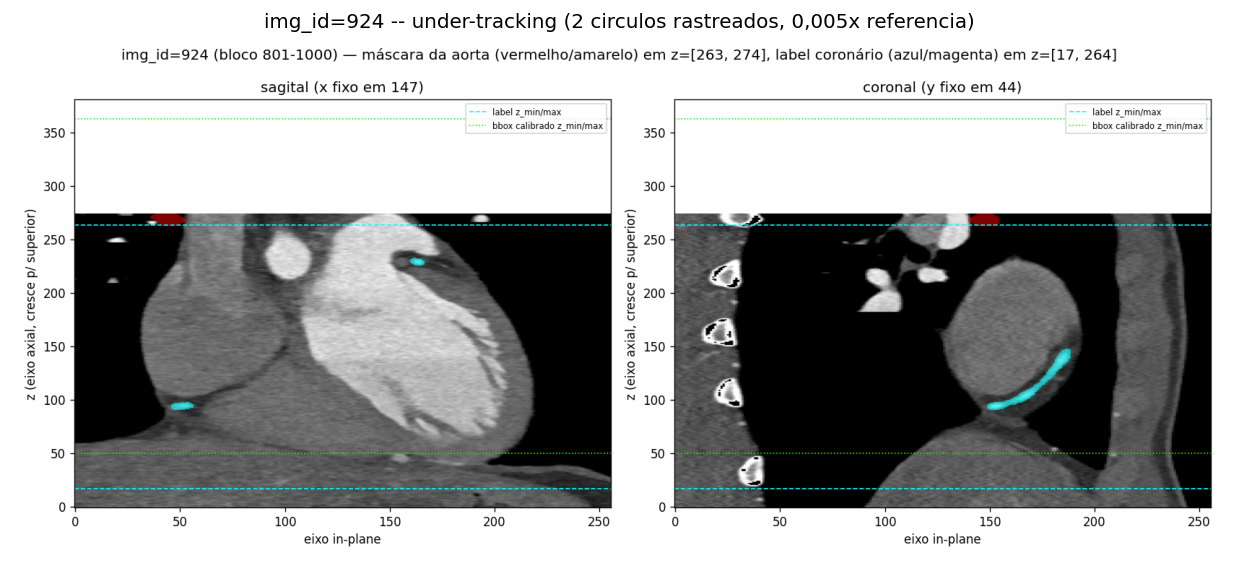

In [8]:
img = mpimg.imread(EXPECTED_FILES["img_924"])
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.imshow(img)
ax.axis("off")
ax.set_title("img_id=924 -- under-tracking (2 circulos rastreados, 0,005x referencia)", fontsize=11)
fig.tight_layout()
plt.show()


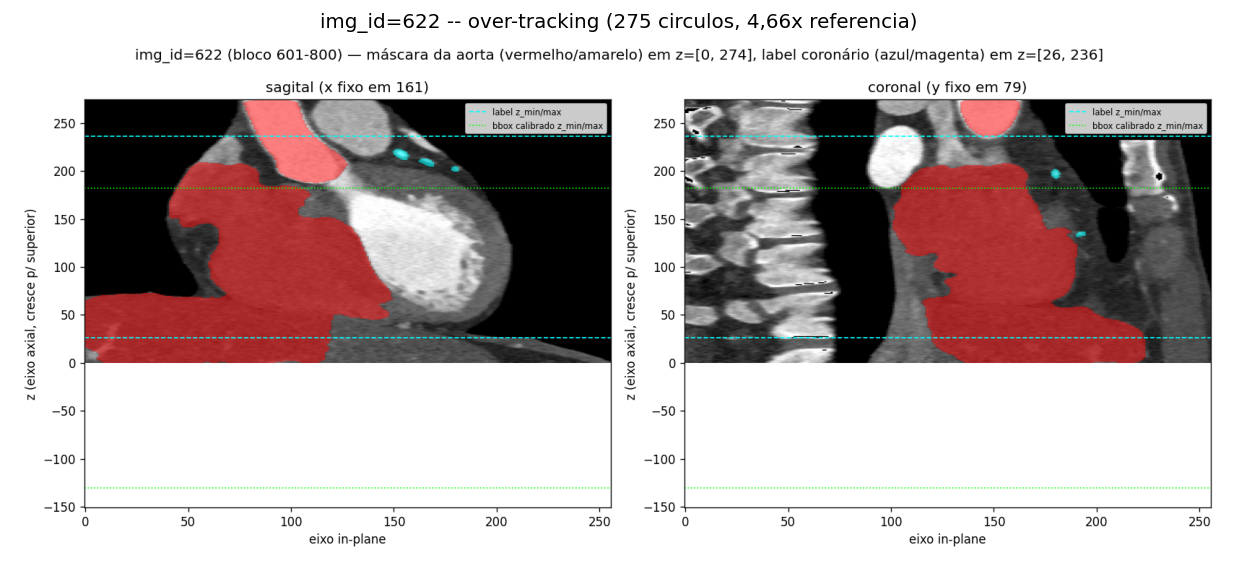

In [9]:
img = mpimg.imread(EXPECTED_FILES["img_622"])
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.imshow(img)
ax.axis("off")
ax.set_title("img_id=622 -- over-tracking (275 circulos, 4,66x referencia)", fontsize=11)
fig.tight_layout()
plt.show()


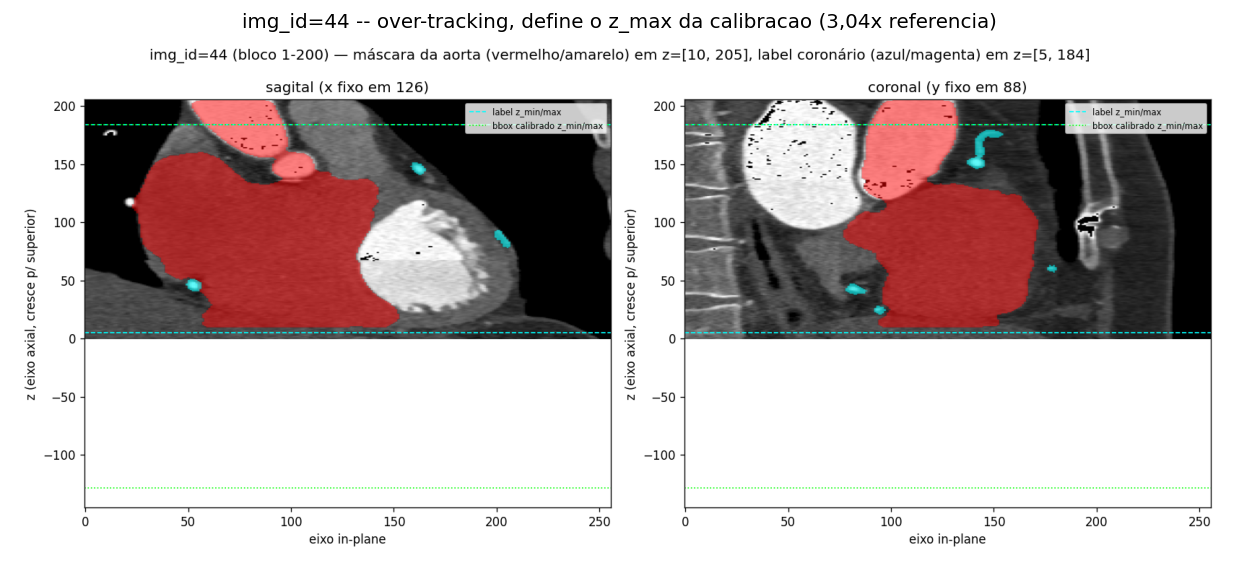

In [10]:
img = mpimg.imread(EXPECTED_FILES["img_44"])
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.imshow(img)
ax.axis("off")
ax.set_title("img_id=44 -- over-tracking, define o z_max da calibracao (3,04x referencia)", fontsize=11)
fig.tight_layout()
plt.show()


**Leitura visual**: em 924, a máscara é um fragmento minúsculo (11 fatias) preso na borda superior
do volume, bem longe do label coronário (lacuna de ~250 fatias) — under-tracking. Em 622 e 44, a
máscara é um blob único e irregular que ocupa boa parte do corte, com formato mais condizente com
outra estrutura (câmara cardíaca) do que com um tubo aórtico — over-tracking/vazamento de
segmentação. Leitura qualitativa, não confirmada contra referência anatômica formal além do label
coronário disponível.

## 5. Timeline de hipóteses testadas

Resumo das três hipóteses mecanísticas investigadas para explicar a falha de cobertura em z, sem
repetir o texto completo de cada seção correspondente em
[docs/step6v2_aorta_anchor.md](../docs/step6v2_aorta_anchor.md).

In [11]:
timeline_rows = [
    {
        "hipótese": "Trocar componente z da âncora: centróide -> z_min (proximal/raiz)",
        "teste": "Amostra estratificada de 50 casos; comparação de dispersão do offset (std, amplitude)",
        "resultado": "Dispersão em z piorou (std -23% a -28%, amplitude -49% a -63%) em vez de melhorar",
        "status": "descartada",
    },
    {
        "hipótese": "'Colar na borda do FOV' (mask_z_max = volume_shape_z - 1) é artefato/sinal dos casos-problema",
        "teste": (
            "Prevalência em amostra de 50 casos + leitura do código-fonte "
            "(detect_aorta_circles sempre começa em num_slices-1) + inspeção HU bruta em 11 casos"
        ),
        "resultado": (
            "Universal por desenho do algoritmo (100% em ambos os grupos); anatomia real e "
            "coerente na última fatia (desfiladeiro torácico), não artefato de reconstrução"
        ),
        "status": "descartada como fator discriminante",
    },
    {
        "hipótese": (
            "Ambiguidade de vasos (múltiplos candidatos de calibre parecido) no desfiladeiro "
            "torácico explica leak/truncamento"
        ),
        "teste": (
            "Métrica objetiva (raio +-20%, distância <2x raio médio) em 15 fatias do topo, "
            "10 casos-problema + 30 casos normais"
        ),
        "resultado": (
            "Distribuições quase totalmente sobrepostas (mediana problema=295 vs. normal=346) - "
            "provável efeito-teto nos limiares da métrica, não confirma nem refuta a hipótese original"
        ),
        "status": "inconclusiva",
    },
]
timeline_df = pd.DataFrame(timeline_rows)
timeline_df


,hipótese,teste,resultado,status
0,Trocar componente z da âncora: centróide -> z_min (proximal/raiz),"Amostra estratificada de 50 casos; comparação de dispersão do offset (std, amplitude)","Dispersão em z piorou (std -23% a -28%, amplitude -49% a -63%) em vez de melhorar",descartada
1,'Colar na borda do FOV' (mask_z_max = volume_shape_z - 1) é artefato/sinal dos casos-problema,Prevalência em amostra de 50 casos + leitura do código-fonte (detect_aorta_circles sempre começa em num_slices-1) + inspeção HU bruta em 11 casos,"Universal por desenho do algoritmo (100% em ambos os grupos); anatomia real e coerente na última fatia (desfiladeiro torácico), não artefato de reconstrução",descartada como fator discriminante
2,Ambiguidade de vasos (múltiplos candidatos de calibre parecido) no desfiladeiro torácico explica leak/truncamento,"Métrica objetiva (raio +-20%, distância <2x raio médio) em 15 fatias do topo, 10 casos-problema + 30 casos normais","Distribuições quase totalmente sobrepostas (mediana problema=295 vs. normal=346) - provável efeito-teto nos limiares da métrica, não confirma nem refuta a hipótese original",inconclusiva


## 6. Perguntas em aberto para a reunião

Sem recomendação fechada — pontos para discutir com o orientador:

- **Continuar investigando o mecanismo exato** (ambiguidade de vasos no desfiladeiro torácico,
  com uma métrica corrigida — a testada em 2026-07-27 teve efeito-teto) **vs. pausar essa linha e
  testar direto um filtro de plausibilidade** (ex.: excluir/sinalizar casos com volume da máscara
  ou `num_circles_detected` fora de uma faixa plausível) na calibração, medindo o efeito resultante
  em `Rv` e cobertura diretamente — sem precisar entender o mecanismo primeiro.

- **Item separado, independente da decisão acima**: o texto da qualificação afirma que a validação
  do LCC confirmou isolamento consistente do coração. Isso já foi contrariado empiricamente
  (`docs/step6_envelope.md`, achado de 2026-07-17 — o LCC nunca isolou o coração, sempre foi
  limpeza grosseira antes da localização da aorta) e precisa de revisão textual na qualificação,
  independente de qualquer decisão sobre a investigação da cobertura em z.